# 27장 · LangGraph 조건부 간선과 재검색

조건부 간선은 상태에 따라 서로 다른 노드로 이어집니다. 빈 검색 결과를 다시 찾게 할 때는 반복을 끝낼 조건도 필요합니다.

‘책을 빌리는 기간?’에는 검색 낱말 ‘대출’이 없습니다. 한 번은 질문을 고쳐 다시 찾되 같은 실패가 끝없이 이어지지 않도록 검색 횟수를 상태에 남깁니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langgraph 1.2.16입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## add_conditional_edges()와 라우팅 함수

search가 시도 횟수를 올린 직후 route가 문서 유무와 attempts를 읽습니다. 문서가 있으면 답을 쓰고, 없고 한 번만 찾았다면 검색어를 바꿉니다. 두 번 찾고도 빈 목록이면 멈춥니다.

**조건부 간선에서 선택되는 경로**　선로가 갈라지는 지점에서 열차는 한쪽으로만 갑니다. route()의 반환값을 바꾸면 어느 노드가 실행되는지 코드와 대조하세요.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter27/index.html#concept-clip)


### 첫 검색에서 문서가 있으면 재작성 간선을 건너뜁니다

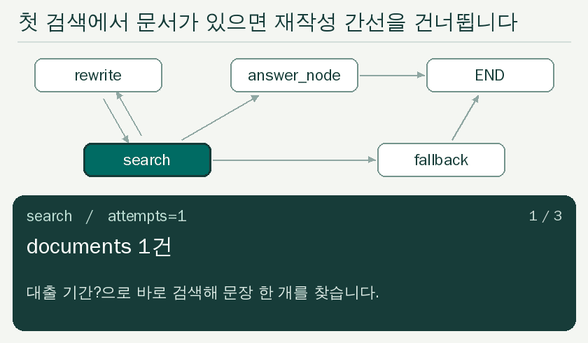

질문에 대출이라는 낱말이 이미 있습니다. route에 들어온 attempts가 1이어도 documents를 먼저 검사하므로 rewrite로 가지 않습니다.


### 셀 01 · route()의 분기 반환값

검색을 한 번 마쳤고 문서를 못 찾았습니다. 다음에 갈 곳을 고르는 함수만 먼저 실행하세요.


In [1]:
def route(state):
    if state["documents"]:
        return "answer"
    if state["attempts"] < 2:
        return "retry"
    return "stop"

after_search = {'question': '책을 빌리는 기간?', 'documents': [], 'answer': '', 'attempts': 1}
print(route(after_search))

retry


retry가 나왔습니다. 이 함수는 검색을 실행하지 않고 다음 경로의 이름만 돌려줍니다. 다음 제공 셀에서 retry와 rewrite가 연결되는 줄을 찾아보세요.


### 조건 함수의 경로 이름

<p>search가 documents를 갱신한 뒤 route가 현재 상태를 읽습니다. route의 역할은 답변을 만드는 것이 아니라 answer·retry·stop 중 한 문자열을 반환하는 것입니다. add_conditional_edges의 대응표가 그 문자열을 등록한 노드 이름과 연결합니다.</p>

<p>직접 성공에서는 한 번 검색하고 종료합니다. 실패라고 무조건 다시 검색하면 같은 입력과 결과를 끝없이 반복할 수 있습니다. 이번 예제는 문서가 없고 attempts가 2보다 작을 때만 재시도합니다.</p>


## 질의 재작성과 재검색 횟수 제한

질문을 고치는 함수가 여러 번 불려도 검색 횟수와 같으리라는 보장은 없습니다. 실제 검색을 실행한 search에서만 attempts를 하나 올립니다. 반복을 제한하는 판단은 이 갱신이 반영된 뒤에 내립니다.

**검색 상태에 따른 다음 노드**　첫 검색 결과가 비면 재검색하고 두 번째에도 비면 종료합니다.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter27/index.html#practice-space)


### 셀 02 · add_conditional_edges()로 경로 등록

이미 실행한 route는 그대로 씁니다. search가 attempts를 올리는 줄과 rewrite 뒤에 다시 search로 돌아가는 엣지를 찾아보세요.

셀 01에서 나온 retry는 아직 최종 답이 아닙니다. 그래프는 rewrite로 이동한 뒤 search에 다시 들어갑니다. 다음 검색에서도 비었을 때 어떤 조건이 반복을 끝내는지 찾아보세요.


In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    documents: list[str]
    answer: str
    attempts: int

def search(state: State) -> dict:
    if not state["question"].strip():
        raise ValueError("질문을 입력하세요.")
    documents = ["도서 대출 기간은 14일입니다."] if "대출" in state["question"] else []
    return {"documents": documents, "attempts": state["attempts"] + 1}

def rewrite(state: State) -> dict:
    return {"question": state["question"].replace("책", "대출")}

def answer(state: State) -> dict:
    return {"answer": " / ".join(state["documents"])}

def fallback(state: State) -> dict:
    return {"answer": "두 번 검색했지만 근거가 없습니다. 질문을 구체화해 주세요."}

def make_graph():
    builder = StateGraph(State)
    for name, node in [("search", search), ("rewrite", rewrite),
                       ("answer_node", answer), ("fallback", fallback)]:
        builder.add_node(name, node)
    builder.add_edge(START, "search")
    builder.add_conditional_edges("search", route,
        {"answer": "answer_node", "retry": "rewrite", "stop": "fallback"})
    builder.add_edge("rewrite", "search")
    builder.add_edge("answer_node", END)
    builder.add_edge("fallback", END)
    return builder.compile()

def run(question: str) -> State:
    initial: State = {"question": question, "documents": [], "answer": "", "attempts": 0}
    return make_graph().invoke(initial, config={"recursion_limit": 20})

print(search(after_search)['attempts'])

2


같은 상태에서 검색을 한 번 더 실행해 횟수가 2가 됐습니다. 이 셀의 함수 정의를 다음 셀에서 사용합니다.


### 상태에 저장하는 시도 횟수

<p>State에 attempts 정수 필드를 추가합니다. 초기 값 0에서 시작해 search가 실제 실행될 때마다 1을 더합니다. 검색 함수 실행 후 route가 읽는 값은 이미 증가한 값입니다. 첫 번째 실패 뒤에는 1이므로 재시도하고, 두 번째 실패 뒤에는 2이므로 종료합니다.</p>

<p>attempts는 이 예제에서 검색 노드 실행 횟수입니다. 전체 노드 수나 모델 토큰 수가 아닙니다. 답변 노드와 rewrite 실행을 함께 세고 싶다면 별도의 기록을 설계해야 합니다.</p>


### 재검색 순환 간선

<p>rewrite 다음에 search로 돌아가는 연결이 반복을 만듭니다. answer_node와 fallback은 END로 연결되어 더 이상 돌아가지 않습니다. 모든 경우를 반복으로 처리하지 않고 성공과 포기 경로를 분리합니다.</p>


### 한 번 고친 질문이 두 번째 검색에서 성공합니다

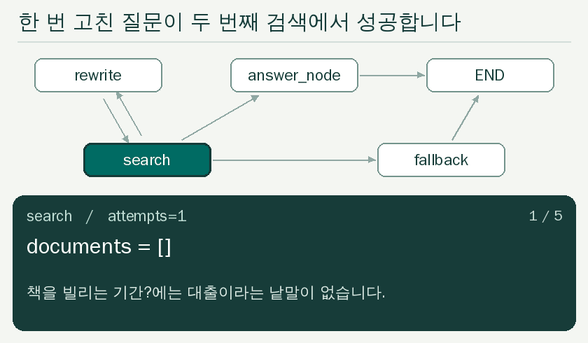

route의 retry는 rewrite 노드를 선택합니다. 다음 search가 비어 있지 않은 documents를 돌려주면 answer 경로로 바뀝니다.


### 셀 03 · rewrite 노드의 질의 변경

질문 한 건의 마지막 상태에서 횟수와 답을 확인하세요.


In [3]:
result = run('책을 빌리는 기간?')
print(result['attempts'], result['answer'])

2 도서 대출 기간은 14일입니다.


두 번째 검색에서 ‘대출’이 들어 있는 질문으로 문장을 찾았습니다. 첫 번째 빈 결과만 보고 바로 끝냈다면 14일이라는 답까지 가지 못했을 것입니다.


### 상태표의 세 종료 경로

<table><caption>관찰할 경로</caption><thead><tr><th scope="col">입력</th><th scope="col">노드 순서</th><th scope="col">검색 횟수</th></tr>
</thead><tbody><tr><td>대출 기간?</td><td>search → answer_node</td><td>1</td></tr>
<tr><td>책을 빌리는 기간?</td><td>search → rewrite → search → answer_node</td><td>2</td></tr>
<tr><td>주차장은?</td><td>search → rewrite → search → fallback</td><td>2</td></tr>
</tbody></table>

<p>두 번째 입력은 첫 검색에서 대출이라는 글자가 없어 실패합니다. rewrite가 책을 대출로 바꾼 뒤 다시 검색하면 근거가 생깁니다. 세 번째 입력은 rewrite로 바뀌지 않아도 횟수 상한으로 끝납니다. 질문이 달라진 사실과 답변이 좋아진 사실은 따로 확인해야 합니다.</p>


### 과제 04 · 검색 상한과 fallback

주차장 질문을 처리한 뒤 몇 번 검색했고 사용자에게 무엇을 안내하는지 출력하세요.


In [4]:
# 주차장 질문을 run에 전달하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>result = run(&#x27;주차장은?&#x27;)
print(result[&#x27;attempts&#x27;], result[&#x27;answer&#x27;])</code></pre>
<p>실행 결과</p><pre><code>2 두 번 검색했지만 근거가 없습니다. 질문을 구체화해 주세요.</code></pre>
<p>두 번 모두 문서가 비어 fallback으로 갑니다. attempts가 2일 때도 retry로 보내면 설계한 상한을 넘게 됩니다. 프레임워크의 recursion_limit은 이런 실수를 발견하는 별도 보호 장치입니다.</p>
</details>


### 반복 상한과 실행 오류

<p>recursion_limit은 그래프 진행을 제한하는 별도의 안전 한도입니다. 이 예제의 검색 최대 횟수 2는 route의 조건으로 정합니다. recursion_limit=20을 검색 20회나 모델 호출 20회로 읽지 마세요. 재시도가 허용되는 업무 조건을 이 값 하나에 맡기지 않습니다.</p>

<p>빈 질문은 search에서 ValueError로 중단됩니다. 질문 자체가 없는데 재검색해도 정보가 늘지 않으므로 입력을 고치도록 합니다. 실제 네트워크 오류의 재시도 여부는 오류 종류·시간 제한·중복 실행 위험을 함께 판단해야 하며 이 장의 로컬 예제로 이를 검증했다고 주장하지 않습니다.</p>

<table><caption>오류 점검</caption><thead><tr><th scope="col">증상</th><th scope="col">확인</th><th scope="col">수정 방향</th></tr>
</thead><tbody><tr><td>끝나지 않거나 GraphRecursionError</td><td>attempts 증가·route 상한</td><td>검색 후 증가와 stop 연결 확인</td></tr>
<tr><td>경로 이름 오류</td><td>route 문자열·대응표·등록 이름</td><td>세 위치를 함께 비교</td></tr>
<tr><td>두 번 성공인데 실패 답변</td><td>조건 검사 순서</td><td>documents 성공 조건 우선</td></tr>
<tr><td>빈 질문 ValueError</td><td>입력 값</td><td>공백이 아닌 질문 입력</td></tr>
<tr><td>항상 문서 없음</td><td>키워드 포함 검사</td><td>가상 검색의 정확한 조건 확인</td></tr>
</tbody></table>


### 분기 하나를 바꾼 뒤 비교할 세 입력

<p>대출 기간?, 책을 빌리는 기간?, 주차장은?을 각각 실행하면 즉시 성공, 재작성 후 성공, 두 번째 검색 후 종료를 구별할 수 있습니다. 종료 안내가 맞아도 검색 횟수가 예상과 다르면 route의 조건 순서를 다시 보세요.</p>


### 주차 질문은 같은 간선을 돌고도 fallback으로 끝납니다

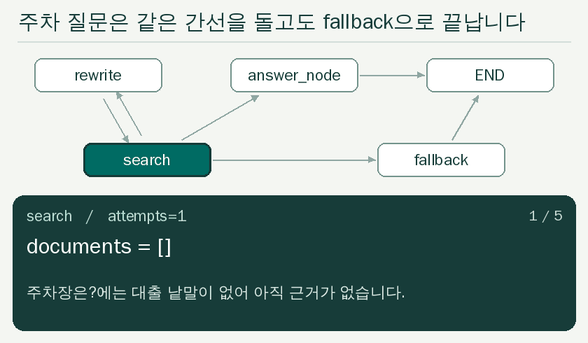

같은 재검색 경로에서 질문이 바뀌지 않을 수 있습니다. 두 번째 빈 결과에서는 route가 stop을 반환해 fallback으로 이어집니다.


## 돌아보기

검색 한 번에 바로 답하는 질문도 골라 보세요. 세 질문 모두 search 다음에 route를 거칩니다. 어떤 상태에서 다음 경로가 갈라졌나요?
